# Vietnamese Emotion Classification - Data Augmentation with LLMs

## 🎯 Goals
1. Generate synthetic training data to balance classes
2. Increase dataset diversity and size
3. Improve model robustness

## 🔧 Features
- **Google Gemini** integration via LangChain
- **Batch processing** with async parallel requests
- **Few-shot prompting** for quality generation

## 📊 Dataset
- 7 emotions: Enjoyment, Disgust, Other, Sadness, Anger, Fear, Surprise
- Vietnamese social media text

## 1️⃣ Installation & Setup

In [1]:
%pip install -q langchain langchain-google-genai langchain-openai python-dotenv pandas tqdm nest_asyncio
print("✅ Packages installed successfully!")


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip3.11 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
✅ Packages installed successfully!


In [2]:
import os
import sys
import asyncio
import pandas as pd
import numpy as np
from typing import List, Dict, Tuple
import time
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import nest_asyncio

from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from dotenv import load_dotenv

nest_asyncio.apply()
print("✅ Libraries imported successfully!")

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Libraries imported successfully!


## 2️⃣ Configuration

In [3]:
from pathlib import Path

def find_tm_research_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if p.name == 'tm_research':
            return p
        if (p / 'tm_research').is_dir():
            return p / 'tm_research'
    raise RuntimeError('Set TM_REPO_ROOT or run from repo checkout')

TM_ROOT = find_tm_research_root()
DATA_DIR = TM_ROOT / 'data' / 'processed'

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("📍 Running in Google Colab")
    from google.colab import userdata
    try:
        GOOGLE_API_KEY = userdata.get('GOOGLE_API_KEY')
        print("✅ Loaded Google Gemini API key from Colab Secrets")
    except:
        from getpass import getpass
        GOOGLE_API_KEY = getpass("Enter your Google Gemini API Key: ")
    os.environ['GOOGLE_API_KEY'] = GOOGLE_API_KEY
else:
    print("📍 Running locally")
    load_dotenv(TM_ROOT / '.env')
    if not os.getenv('GOOGLE_API_KEY'):
        print("⚠️ Warning: No GOOGLE_API_KEY found in .env file")
    else:
        print("✅ Loaded Google Gemini API key from .env file")

print("✅ Configuration complete!")

📍 Running locally
✅ Loaded Google Gemini API key from .env file
✅ Configuration complete!


## 3️⃣ Load and Explore Data

In [4]:
# if IN_COLAB:
#     from google.colab import drive
#     drive.mount('/content/drive')
#     data_path = '/content/drive/MyDrive/thesis/data/train_nor_811.xlsx'
#     df_train = pd.read_excel(data_path)
# else:
#     data_path = './data/processed/train_org_processed.csv'
#     df_train = pd.read_csv(data_path)

# print(f"📊 Loaded {len(df_train)} training samples")
# print(f"📋 Columns: {df_train.columns.tolist()}")
# df_train.head()

In [5]:
df_train = pd.read_csv(DATA_DIR / 'train_org_processed.csv')
df_train.head()
# Drop the Sentence_clean column if it exists
if 'Sentence_clean' in df_train.columns:
    df_train = df_train.drop('Sentence_clean', axis=1)
    print("✅ Dropped 'Sentence_clean' column")
else:
    print("ℹ️ 'Sentence_clean' column not found")

print(f"📋 Updated columns: {df_train.columns.tolist()}")


ℹ️ 'Sentence_clean' column not found
📋 Updated columns: ['Emotion', 'Sentence', 'emotion_vn']


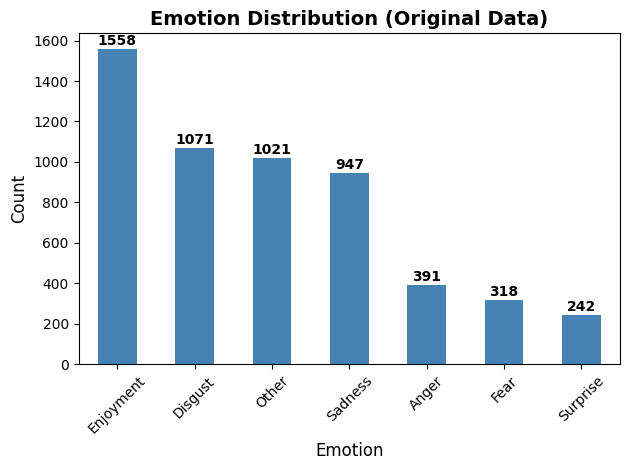

📊 Emotion Statistics:
Emotion
Enjoyment    1558
Disgust      1071
Other        1021
Sadness       947
Anger         391
Fear          318
Surprise      242
Name: count, dtype: int64
⚖️ Imbalance ratio: 6.44x


In [6]:
emotion_counts = df_train['Emotion'].value_counts()

fig, ax1 = plt.subplots()

emotion_counts.plot(kind='bar', ax=ax1, color='steelblue')
ax1.set_title('Emotion Distribution (Original Data)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Emotion', fontsize=12)
ax1.set_ylabel('Count', fontsize=12)
ax1.tick_params(axis='x', rotation=45)
for i, v in enumerate(emotion_counts):
    ax1.text(i, v + 20, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print(f"📊 Emotion Statistics:")
print(emotion_counts)
print(f"⚖️ Imbalance ratio: {emotion_counts.max() / emotion_counts.min():.2f}x")

In [7]:
print("📝 Sample texts for each emotion:")
for emotion in df_train['Emotion'].unique():
    samples = df_train[df_train['Emotion'] == emotion]['Sentence'].head(2).tolist()
    print(f"{'='*60}")
    print(f"🏷️  {emotion}")
    print(f"{'='*60}")
    for i, text in enumerate(samples, 1):
        print(f"{i}. {text}")

📝 Sample texts for each emotion:
🏷️  Other
1. cho mình xin bài nhạc tên là gì với ạ
2. một lí do trog muôn vàn lí do
🏷️  Disgust
1. cho đáng đời con quỷ . về nhà lôi con nhà mày ra mà đánh 😡
2. lo học đi . yêu đương lol gì hay lại thích học sinh học
🏷️  Enjoyment
1. uớc gì sau này về già vẫn có thể như cụ này :))
2. mỗi lần có video của con là cứ coi đi coi lại hoài . cưng con quá .
🏷️  Anger
1. thằng kia sao mày bắt vợ với bồ tao dọn thế kia . nhà mày ở đâu tao đến thịt mày chết
2. ko phải con mình , mà xem còn thấy đau như vậy huống gì người trong cuộc . thật là phẫn nộ mà . cơ quan chức năng làm việc quá chậm trễ , đến giờ mà vẫn chưa tìm ra người chịu trách nhiệm . 😠😠😠😠😠😠
🏷️  Surprise
1. thật hay đùa ác vậy . không thể tin được
2. per đây mí chính là cụ tổ của những chiếc sừng này
🏷️  Sadness
1. per nghe đi rồi khóc 1 trận cho thoải mái . đừng cố gồng mình lên nữa
2. tui thi ́ ch va ̉ i lă ́ mày ma ̀ ăn nhỉ ̀ u no ́ người lă ́ mày mọi người anh ̣ , bi ̣ lơ ̉ miê ̣ người
🏷️  Fear
1.

## 4️⃣ Batch Augmenter Class

Uses **LangChain's async batch processing** for efficient parallel API requests.

**Key Benefits:**
- Parallel processing reduces total execution time
- Rate limiting built-in to avoid API quota issues
- Few-shot prompting with random examples for diversity

In [8]:
# class BatchEmotionAugmenterLangChain:
#     """Batch data augmentation for Vietnamese emotion classification using LangChain's abatch()."""
    
#     EMOTIONS = {
#         'Enjoyment': 'vui vẻ', 'Disgust': 'khó chịu', 'Other': 'khác',
#         'Sadness': 'buồn', 'Anger': 'giận dữ', 'Fear': 'sợ hãi', 'Surprise': 'ngạc nhiên'
#     }
    
#     def __init__(self, df: pd.DataFrame, model_name: str = "gemini-2.5-flash", 
#                  temperature: float = 0.9, max_concurrency: int = 5, verbose: bool = True, freq_penalty: float = 0.5):
#         self.df = df
#         self.model_name = model_name
#         self.temperature = temperature
#         self.max_concurrency = max_concurrency
#         self.verbose = verbose
#         self.freq_penalty = freq_penalty
#         self.llm = ChatGoogleGenerativeAI(
#         model=model_name, temperature=temperature,
#         frequency_penalty=freq_penalty,  # LangChain uses frequency_penalty
#         google_api_key=os.getenv("GOOGLE_API_KEY")
#     )
        
#         self.prompt = ChatPromptTemplate.from_messages([
#             ("system", """You are an expert in Vietnamese Gen Z language, social media writing style.
# Your task is to generate Vietnamese sentences while STRICTLY preserving:
# - Core semantic meaning
# - Emotional tone and intensity
# - Speaker intent




# All outputs must sound natural, realistic, and suitable for Vietnamese social media.
# Do NOT introduce new facts, entities, time references, causes, or consequences.
# Do NOT change sentiment polarity or emotional strength.
# Use slang or emoji sparingly and only when they feel natural.
# - DO NOT REPLACE: emotional particles (nhé, ạ, mà), negations (không, chẳng)
# - ONLY augment: content words, not structure words
# - Preserve: emotional intensifiers (rất, lắm, quá)
# """),
#             ("human", """Generate exactly {num_variations} NEW Vietnamese sentences that preserve the SAME meaning and emotion as the example sentences below.

# Emotion to preserve:
# - English label: "{emotion}"
# - Vietnamese description: "{emotion_vn}"

# Example sentences:
# 1. "{example1}"
# 2. "{example2}"
# 3. "{example3}"
# 4. "{example4}"
# 5. "{example5}"
# 6. "{example6}"
# 7. "{example7}"
# 8. "{example8}"
# 9. "{example9}"
# 10. "{example10}"

# SEMANTIC SIMILARITY CONSTRAINTS (MANDATORY):
# 1. Each generated sentence must be semantically equivalent to its source example:
#    - No addition or removal of key actions, intentions, or outcomes
# 2. Preserve:
#    - Subject (implicit or explicit)
#    - Action/state
#    - Target/object (if any)
#    - Cause–effect relationship (if present)
# 3. Allowed changes:
#    - Word choice (synonyms, paraphrasing)
#    - Sentence structure (active/passive, reordering)
#    - Discourse markers or softeners common in Gen Z Vietnamese
# 4. Forbidden changes:
#    - Changing who is speaking or being referenced
#    - Adding sarcasm if not present in the original
#    - Adding intensity (e.g., “rất”, “quá trời”) unless present originally
#    - Introducing new emotions or mixed emotions

# STYLE & LENGTH CONSTRAINTS:
# 5. Length variation is required across outputs:
#    - Short: 5–10 words
#    - Medium: 10–20 words
#    - Long: 20+ words
# 6. All sentences must be in Vietnamese.
# 7. Gen Z style must be natural, not exaggerated.
# 8. Emojis or slang:
#    - Optional
#    - Maximum 1 emoji per sentence
#    - Must not change semantic meaning or emotion

# OUTPUT FORMAT (STRICT):
# Each line must follow this exact format:
# [number]. [new Vietnamese sentence] (example [source_number])

# Where:
# - [number] is 1 to {num_variations}
# - [source_number] is 1 to 10 (indicating which example sentence was paraphrased)

# Example output format:
# 1. câu tiếng việt mới (example 1)
# 2. một câu khác (example 7)

# Rules:
# - One sentence per line
# - No explanations, notes, or extra text
# - Always include (example X) at the end where X is 1 to 10
# """)
#         ])
        
#         self.chain = self.prompt | self.llm
#         if self.verbose:
#             print(f"✅ Initialized BatchEmotionAugmenterLangChain with {model_name}")
    
#     def _get_few_shot_examples(self, emotion: str, num_examples: int = 10) -> List[str]:
#         emotion_df = self.df[self.df['Emotion'] == emotion]
#         replace = len(emotion_df) < num_examples
#         return emotion_df['Sentence'].sample(n=num_examples, replace=replace).tolist()
    
#     def _parse_generated_text(self, text: str, examples: List[str] = None) -> List[Dict[str, str]]:
#         import re
#         results = []
#         for line in text.strip().split('\n'):
#             line = line.strip()
#             if not line:
#                 continue
#             source_match = re.search(r'\((?:example\s*)?(\d+)\)\s*$', line, re.IGNORECASE)
#             source_idx = int(source_match.group(1)) if source_match else None
#             if source_match:
#                 line = line[:source_match.start()].strip()
#             if line and line[0].isdigit() and '. ' in line:
#                 line = line.split('. ', 1)[-1]
#             sentence = line.strip()
#             if sentence:
#                 result = {'sentence': sentence, 'source_example_idx': source_idx}
#                 result['source_example'] = examples[source_idx - 1] if examples and source_idx and 1 <= source_idx <= len(examples) else None
#                 results.append(result)
#         return results
    
#     def prepare_batch_inputs(self, emotions_to_augment: List[str] = None,
#                             num_variations_per_call: int = 5, num_calls_per_emotion: int = 10) -> List[Tuple[str, dict]]:
#         emotions = emotions_to_augment or list(self.EMOTIONS.keys())
#         inputs = []
#         for emotion in emotions:
#             for _ in range(num_calls_per_emotion):
#                 examples = self._get_few_shot_examples(emotion, 10)
#                 inputs.append((emotion, {
#                     "emotion": emotion, "emotion_vn": self.EMOTIONS.get(emotion, emotion),
#                     "example1": examples[0], "example2": examples[1], "example3": examples[2],
#                     "example4": examples[3], "example5": examples[4], "example6": examples[5],
#                     "example7": examples[6], "example8": examples[7], "example9": examples[8],
#                     "example10": examples[9],
#                     "num_variations": num_variations_per_call, "_examples": examples
#                 }))
#         if self.verbose:
#             print(f"📝 Prepared {len(inputs)} batch inputs (~{len(inputs) * num_variations_per_call} samples)")
#         return inputs
    
#     async def _run_batch_async(self, inputs: List[Tuple[str, dict]], delay: float = 1.0):
#         results = []
#         for i in range(0, len(inputs), self.max_concurrency):
#             chunk = inputs[i:i + self.max_concurrency]
#             if self.verbose:
#                 print(f"   Batch {i//self.max_concurrency + 1}/{(len(inputs) + self.max_concurrency - 1)//self.max_concurrency}...")
#             try:
#                 responses = await self.chain.abatch([d for _, d in chunk], config={"max_concurrency": self.max_concurrency})
#                 for (emotion, input_dict), response in zip(chunk, responses):
#                     results.append((emotion, response.content, input_dict.get('_examples', [])))
#             except Exception as e:
#                 print(f"⚠️ Error: {e}")
#                 for emotion, _ in chunk:
#                     results.append((emotion, "", []))
#             if i + self.max_concurrency < len(inputs):
#                 await asyncio.sleep(delay)
#         return results
    
#     def run_batch_augmentation(self, emotions_to_augment: List[str] = None, num_variations_per_call: int = 5,
#                                num_calls_per_emotion: int = 10, delay_between_batches: float = 1.0) -> pd.DataFrame:
#         if self.verbose:
#             print(f"🚀 Starting batch augmentation...")
#         inputs = self.prepare_batch_inputs(emotions_to_augment, num_variations_per_call, num_calls_per_emotion)
#         results = asyncio.run(self._run_batch_async(inputs, delay_between_batches))
        
#         rows = []
#         for emotion, text, examples in results:
#             if text:
#                 for item in self._parse_generated_text(text, examples):
#                     if item['sentence'].strip():
#                         rows.append({
#                             'Emotion': emotion, 'Sentence': item['sentence'].strip(),
#                             'emotion_vn': self.EMOTIONS.get(emotion, ''), 'augmented': True,
#                             'source': 'langchain_batch', 'source_example_idx': item.get('source_example_idx'),
#                             'source_example': item.get('source_example')
#                         })
        
#         df = pd.DataFrame(rows)
#         if self.verbose:
#             print(f"✅ Generated {len(df)} samples")
#             if len(df) > 0:
#                 print(df['Emotion'].value_counts())
#         return df
    
#     def combine_with_original(self, augmented_df: pd.DataFrame) -> pd.DataFrame:
#         df_orig = self.df.copy()
#         df_orig['augmented'] = False
#         df_orig['source'] = 'original'
#         combined = pd.concat([df_orig, augmented_df], ignore_index=True)
#         if self.verbose:
#             print(f"✅ Combined: {len(self.df)} original + {len(augmented_df)} augmented = {len(combined)} total")
#         return combined

# print("✅ BatchEmotionAugmenterLangChain class defined!")

In [9]:
class BatchEmotionAugmenterLangChain:
    """Batch data augmentation for Vietnamese emotion classification using LangChain's abatch()."""
    
    EMOTIONS = {
        'Enjoyment': 'vui vẻ', 'Disgust': 'khó chịu', 'Other': 'khác',
        'Sadness': 'buồn', 'Anger': 'giận dữ', 'Fear': 'sợ hãi', 'Surprise': 'ngạc nhiên'
    }
    
    def __init__(self, df: pd.DataFrame, model_name: str = "gemini-2.5-flash", 
                 temperature: float = 0.7, max_concurrency: int = 5, verbose: bool = True):
        self.df = df
        self.model_name = model_name
        self.temperature = temperature
        self.max_concurrency = max_concurrency
        self.verbose = verbose
        
        self.llm = ChatGoogleGenerativeAI(
            model=model_name, temperature=temperature,
            google_api_key=os.getenv("GOOGLE_API_KEY")
        )
        
        self.prompt = ChatPromptTemplate.from_messages([
            ("system", """You are an expert in Vietnamese language, social media writing style.
Your task is to generate Vietnamese sentences that is related to the given emotion while STRICTLY following the rules below:

- All outputs must sound natural, realistic, and suitable for Vietnamese social media.
- Only generate sentences that express the given emotion.
- Use slang or emoji sparingly and only when they feel natural.
"""),
            ("human", """Generate exactly {num_variations} NEW Vietnamese sentences that express the given emotion as the example sentences below.

Emotion to generate:
- English label: "{emotion}"
- Vietnamese description: "{emotion_vn}"

Example sentences:
1. "{example1}"
2. "{example2}"
3. "{example3}"
4. "{example4}"
5. "{example5}"
6. "{example6}"
7. "{example7}"
8. "{example8}"
9. "{example9}"
10. "{example10}"

STYLE & LENGTH CONSTRAINTS:
5. Length variation is required across outputs:
   - Short: 5–10 words
   - Medium: 10–20 words
   - Long: 20+ words
6. All sentences must be in Vietnamese.
7. Your sentence must not contain any other emotion than the given emotion.


OUTPUT FORMAT (STRICT):
Each line must follow this exact format:
[number]. [new Vietnamese sentence] (example [source_number])

Where:
- [number] is 1 to {num_variations}
- [source_number] is 1 to 10 (indicating which example sentence was paraphrased)

Example output format:
1. câu tiếng việt mới (example 1)
2. một câu khác (example 7)

Rules:
- One sentence per line
- No explanations, notes, or extra text
- Always include (example X) at the end where X is 1 to 10
""")
        ])
        
        self.chain = self.prompt | self.llm
        if self.verbose:
            print(f"✅ Initialized BatchEmotionAugmenterLangChain with {model_name}")
    
    def _get_few_shot_examples(self, emotion: str, num_examples: int = 10) -> List[str]:
        emotion_df = self.df[self.df['Emotion'] == emotion]
        replace = len(emotion_df) < num_examples
        return emotion_df['Sentence'].sample(n=num_examples, replace=replace).tolist()
    
    def _parse_generated_text(self, text: str, examples: List[str] = None) -> List[Dict[str, str]]:
        import re
        results = []
        for line in text.strip().split('\n'):
            line = line.strip()
            if not line:
                continue
            source_match = re.search(r'\((?:example\s*)?(\d+)\)\s*$', line, re.IGNORECASE)
            source_idx = int(source_match.group(1)) if source_match else None
            if source_match:
                line = line[:source_match.start()].strip()
            if line and line[0].isdigit() and '. ' in line:
                line = line.split('. ', 1)[-1]
            sentence = line.strip()
            if sentence:
                result = {'sentence': sentence, 'source_example_idx': source_idx}
                result['source_example'] = examples[source_idx - 1] if examples and source_idx and 1 <= source_idx <= len(examples) else None
                results.append(result)
        return results
    
    def prepare_batch_inputs(self, emotions_to_augment: List[str] = None,
                            num_variations_per_call: int = 5, num_calls_per_emotion: int = 10) -> List[Tuple[str, dict]]:
        emotions = emotions_to_augment or list(self.EMOTIONS.keys())
        inputs = []
        for emotion in emotions:
            for _ in range(num_calls_per_emotion):
                examples = self._get_few_shot_examples(emotion, 10)
                inputs.append((emotion, {
                    "emotion": emotion, "emotion_vn": self.EMOTIONS.get(emotion, emotion),
                    "example1": examples[0], "example2": examples[1], "example3": examples[2],
                    "example4": examples[3], "example5": examples[4], "example6": examples[5],
                    "example7": examples[6], "example8": examples[7], "example9": examples[8],
                    "example10": examples[9],
                    "num_variations": num_variations_per_call, "_examples": examples
                }))
        if self.verbose:
            print(f"📝 Prepared {len(inputs)} batch inputs (~{len(inputs) * num_variations_per_call} samples)")
        return inputs
    
    async def _run_batch_async(self, inputs: List[Tuple[str, dict]], delay: float = 1.0):
        results = []
        for i in range(0, len(inputs), self.max_concurrency):
            chunk = inputs[i:i + self.max_concurrency]
            if self.verbose:
                print(f"   Batch {i//self.max_concurrency + 1}/{(len(inputs) + self.max_concurrency - 1)//self.max_concurrency}...")
            try:
                responses = await self.chain.abatch([d for _, d in chunk], config={"max_concurrency": self.max_concurrency})
                for (emotion, input_dict), response in zip(chunk, responses):
                    results.append((emotion, response.content, input_dict.get('_examples', [])))
            except Exception as e:
                print(f"⚠️ Error: {e}")
                for emotion, _ in chunk:
                    results.append((emotion, "", []))
            if i + self.max_concurrency < len(inputs):
                await asyncio.sleep(delay)
        return results
    
    def run_batch_augmentation(self, emotions_to_augment: List[str] = None, num_variations_per_call: int = 5,
                               num_calls_per_emotion: int = 10, delay_between_batches: float = 1.0) -> pd.DataFrame:
        if self.verbose:
            print(f"🚀 Starting batch augmentation...")
        inputs = self.prepare_batch_inputs(emotions_to_augment, num_variations_per_call, num_calls_per_emotion)
        results = asyncio.run(self._run_batch_async(inputs, delay_between_batches))
        
        rows = []
        for emotion, text, examples in results:
            if text:
                for item in self._parse_generated_text(text, examples):
                    if item['sentence'].strip():
                        rows.append({
                            'Emotion': emotion, 'Sentence': item['sentence'].strip(),
                            'emotion_vn': self.EMOTIONS.get(emotion, ''), 'augmented': True,
                            'source': 'langchain_batch', 'source_example_idx': item.get('source_example_idx'),
                            'source_example': item.get('source_example')
                        })
        
        df = pd.DataFrame(rows)
        if self.verbose:
            print(f"✅ Generated {len(df)} samples")
            if len(df) > 0:
                print(df['Emotion'].value_counts())
        return df
    
    def combine_with_original(self, augmented_df: pd.DataFrame) -> pd.DataFrame:
        df_orig = self.df.copy()
        df_orig['augmented'] = False
        df_orig['source'] = 'original'
        combined = pd.concat([df_orig, augmented_df], ignore_index=True)
        if self.verbose:
            print(f"✅ Combined: {len(self.df)} original + {len(augmented_df)} augmented = {len(combined)} total")
        return combined

print("✅ BatchEmotionAugmenterLangChain class defined!")

✅ BatchEmotionAugmenterLangChain class defined!


## 5️⃣ Balanced Augmentation Function

In [10]:
def run_balanced_augmentation(batch_augmenter, df_train: pd.DataFrame, target_per_emotion: int = 3000,
                               variations_per_call: int = 5, max_concurrency: int = 50,
                               delay_between_batches: float = 1, min_samples_to_augment: int = 50) -> pd.DataFrame:
    """Generate samples to balance dataset to target count per emotion."""
    current_counts = df_train['Emotion'].value_counts()
    all_augmented = []
    augmentation_plan = []
    
    print("=" * 60)
    print("📊 AUGMENTATION PLAN")
    print("=" * 60)
    
    for emotion in sorted(current_counts.index):
        count = current_counts[emotion]
        if count >= target_per_emotion:
            print(f"✅ {emotion}: {count} (skip - at target)")
            continue
        needed = target_per_emotion - count
        if needed < min_samples_to_augment:
            print(f"⏭️ {emotion}: {count} → {target_per_emotion} (skip - only {needed} needed)")
            continue
        num_calls = -(-needed // variations_per_call)
        augmentation_plan.append({'emotion': emotion, 'needed': needed, 'num_calls': num_calls})
        print(f"🔄 {emotion}: {count} → {target_per_emotion} (need {needed}, {num_calls} calls)")
    
    print("=" * 60)
    if not augmentation_plan:
        print("✅ No augmentation needed!")
        return pd.DataFrame()
    
    original_concurrency = batch_augmenter.max_concurrency
    batch_augmenter.max_concurrency = max_concurrency
    
    for item in augmentation_plan:
        emotion, needed, num_calls = item['emotion'], item['needed'], item['num_calls']
        print(f"🎯 Augmenting: {emotion} ({needed} samples)")
        try:
            aug_df = batch_augmenter.run_batch_augmentation(
                emotions_to_augment=[emotion], num_variations_per_call=variations_per_call,
                num_calls_per_emotion=num_calls, delay_between_batches=delay_between_batches
            )
            if len(aug_df) > 0:
                all_augmented.append(aug_df.head(needed))
                print(f"   ✅ Generated {min(len(aug_df), needed)} samples")
        except Exception as e:
            print(f"   ❌ Error: {e}")
    
    batch_augmenter.max_concurrency = original_concurrency
    
    if not all_augmented:
        return pd.DataFrame()
    
    final = pd.concat(all_augmented, ignore_index=True)
    print(f"🎉 COMPLETE! Total: {len(final)} samples")
    return final

print("✅ run_balanced_augmentation() defined!")

✅ run_balanced_augmentation() defined!


## 6️⃣ Run Augmentation

In [11]:
# Initialize batch augmenter
batch_augmenter = BatchEmotionAugmenterLangChain(
    df=df_train,
    model_name="gemini-2.5-flash-lite",
    temperature=0.9,
    max_concurrency=50,
    verbose=True
)

# Run balanced augmentation
augmented_df = run_balanced_augmentation(
    batch_augmenter=batch_augmenter,
    df_train=df_train,
    target_per_emotion=1500,
    variations_per_call=10,
    max_concurrency=50,
    delay_between_batches=0.5,
    min_samples_to_augment=50
)

# Combine with original and save
combined_df = batch_augmenter.combine_with_original(augmented_df)
combined_df.to_csv(DATA_DIR / 'train_balanced_optimized.csv', index=False)
print(f"💾 Saved to {DATA_DIR / 'train_balanced_optimized.csv'}")

✅ Initialized BatchEmotionAugmenterLangChain with gemini-2.5-flash-lite
📊 AUGMENTATION PLAN
🔄 Anger: 391 → 1500 (need 1109, 111 calls)
🔄 Disgust: 1071 → 1500 (need 429, 43 calls)
✅ Enjoyment: 1558 (skip - at target)
🔄 Fear: 318 → 1500 (need 1182, 119 calls)
🔄 Other: 1021 → 1500 (need 479, 48 calls)
🔄 Sadness: 947 → 1500 (need 553, 56 calls)
🔄 Surprise: 242 → 1500 (need 1258, 126 calls)
🎯 Augmenting: Anger (1109 samples)
🚀 Starting batch augmentation...


E0000 00:00:1780633299.569423 3562176 alts_credentials.cc:93] ALTS creds ignored. Not running on GCP and untrusted ALTS is not enabled.
E0000 00:00:1780633299.670122 3562176 alts_credentials.cc:93] ALTS creds ignored. Not running on GCP and untrusted ALTS is not enabled.


📝 Prepared 111 batch inputs (~1110 samples)
   Batch 1/3...


KeyboardInterrupt: 

## 7️⃣ Post-Processing

In [ ]:
# Load and verify
train_balanced = pd.read_csv(DATA_DIR / 'train_balanced_optimized.csv')

# Fix emotion_vn values
train_balanced['emotion_vn'] = train_balanced['emotion_vn'].replace('buồn bã', 'buồn')

print("📊 Distribution:")
print(train_balanced['emotion_vn'].value_counts())
train_balanced.head()

📊 Distribution:
emotion_vn
vui vẻ        1558
khác          1500
khó chịu      1500
giận dữ       1500
ngạc nhiên    1500
buồn          1500
sợ hãi        1500
Name: count, dtype: int64


,Emotion,Sentence,emotion_vn,augmented,source,source_example_idx,source_example
0,Other,cho mình xin bài nhạc tên là gì với ạ,khác,False,original,NaN,NaN
1,Disgust,cho đáng đời con quỷ . về nhà lôi con nhà mày ...,khó chịu,False,original,NaN,NaN
2,Disgust,lo học đi . yêu đương lol gì hay lại thích học...,khó chịu,False,original,NaN,NaN
3,Enjoyment,uớc gì sau này về già vẫn có thể như cụ này :)),vui vẻ,False,original,NaN,NaN
4,Enjoyment,mỗi lần có video của con là cứ coi đi coi lại ...,vui vẻ,False,original,NaN,NaN


## Export datasets

Two CSV exports from the same `train_balanced` dataframe:

- **`train_1500_gen_eval.csv`** — evaluation / provenance (`augmented`, `source`, trace columns)
- **`train_1500_gen_clean.csv`** — training-ready (trace columns removed)

In [ ]:
# Export eval + clean datasets (run post-processing cell first, or reload here)
if 'train_balanced' not in globals():
    train_balanced = pd.read_csv('./data/processed/train_balanced_optimized.csv')
    train_balanced['emotion_vn'] = train_balanced['emotion_vn'].replace('buồn bã', 'buồn')

# Eval export (metadata for synthetic vs original split)
eval_path = DATA_DIR / 'train_1500_gen_eval.csv'
train_balanced.to_csv(eval_path, index=False, encoding='utf8')

# Clean export (training-ready, same as current pipeline)
trace_cols = ['augmented', 'source', 'source_example_idx', 'source_example']
train_clean = train_balanced.drop(columns=trace_cols, errors='ignore')
clean_path = DATA_DIR / 'train_1500_gen_clean.csv'
train_clean.to_csv(clean_path, index=False, encoding='utf8')

print(f"✅ Saved eval: {eval_path}")
print(f"   Samples: {len(train_balanced)}, columns: {list(train_balanced.columns)}")
print(f"✅ Saved clean: {clean_path}")
print(f"   Samples: {len(train_clean)}, columns: {list(train_clean.columns)}")

✅ Saved eval: ./data/processed/train_1500_gen_eval.csv
   Samples: 10558, columns: ['Emotion', 'Sentence', 'emotion_vn', 'augmented', 'source', 'source_example_idx', 'source_example']
✅ Saved clean: ./data/processed/train_1500_gen_clean.csv
   Samples: 10558, columns: ['Emotion', 'Sentence', 'emotion_vn']


In [ ]:
# Verify final datasets
print("🔍 Final dataset check (clean):")
print(f"   Unique emotions: {train_clean['emotion_vn'].nunique()}")
print(f"   Missing values: {train_clean['emotion_vn'].isnull().sum()}")
print(train_clean['emotion_vn'].value_counts())
print(f"\n   Row count match: eval={len(train_balanced)}, clean={len(train_clean)}")
if "augmented" in train_balanced.columns:
    print("\n📊 augmented flag in eval file:")
    print(train_balanced["augmented"].value_counts())


🔍 Final dataset check (clean):
   Unique emotions: 7
   Missing values: 0
emotion_vn
vui vẻ        1558
khác          1500
khó chịu      1500
giận dữ       1500
ngạc nhiên    1500
buồn          1500
sợ hãi        1500
Name: count, dtype: int64

   Row count match: eval=10558, clean=10558

📊 augmented flag in eval file:
augmented
False    5548
True     5010
Name: count, dtype: int64


## 8️⃣ Cleanup

In [ ]:
import gc
gc.collect()
print("✅ Memory cleared.")

✅ Memory cleared.
